# [13.3] Concept Directions and Diffusion LoRA (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part3_concept_directions_lora/13.3_Concept_Directions_and_Diffusion_LoRA_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part3_concept_directions_lora/13.3_Concept_Directions_and_Diffusion_LoRA_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

A blue square sits on a gray background. Can you turn just the square red, leaving the
background alone? A direction in a hidden state and a direction in weight space are different
objects; both can change the picture, and both can accidentally change something else.

By the end of this notebook, you will have shown that a matched hidden-state direction and a
rank-one linear adapter can change object color in an explicit image generator, because a
pixel-based color score increases while an equal-norm background adapter fails that score.
You will see the images, singular-value spectrum and a behavior/side-effect matrix.

Prerequisites: matrix multiplication, least squares and SVD from chapter 0; forward noising
and the intervention vocabulary of 13.1–13.2. The decoder is deliberately transparent:
its known structure lets us ask whether an intervention is selective before involving a UNet.

## Study-edition boundary

The default path is a small, deterministic CPU organism with explicit weights and finite
images. It teaches the named component operations and controls. It is not a trained diffusion
model, a pretrained checkpoint, or a paper replication. No model download, GPU selection,
training run or scientific sweep occurs.

## Content & Learning Objectives

### 1️⃣ A scene with measurable attributes

Build a small image decoder and score object color independently of its hidden coordinates.

> ##### Learning Objectives
>
> - Implement the visible operations for build a small image decoder and score object color independently of its hidden coordinates.
> - Explain the tensor axes and use an independent small-case check.

### 2️⃣ From paired states to a direction

Extract matched semantic differences and compare target steering with a nuisance direction.

> ##### Learning Objectives
>
> - Implement the visible operations for extract matched semantic differences and compare target steering with a nuisance direction.
> - Explain the tensor axes and use an independent small-case check.

### 3️⃣ What a low-rank adapter changes

Fit one factor of a rank-one adapter exactly, then inspect its singular directions.

> ##### Learning Objectives
>
> - Implement the visible operations for fit one factor of a rank-one adapter exactly, then inspect its singular directions.
> - Explain the tensor axes and use an independent small-case check.

### 4️⃣ Behavior, side effects and transfer

Compare behavior and side effects, then predict a changed direction before running it.

> ##### Learning Objectives
>
> - Implement the visible operations for compare behavior and side effects, then predict a changed direction before running it.
> - Explain the tensor axes and use an independent small-case check.

### ☆ Bonus

Anomaly hunts, the source-grounded model bridge, and further reading.

## Setup code

Use the existing environment and keep the notebook under this checkout. No installation cell
is needed. All arrays use NumPy float64 on CPU. The section-local helpers provide plotting
only; each method, metric, intervention and control is implemented below.

In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = "chapter13_image_generation_interpretability"
section = "part3_concept_directions_lora"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).is_dir())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part3_concept_directions_lora.tests as tests
import part3_concept_directions_lora.utils as utils
MAIN = __name__ == "__main__"

# 1️⃣ A scene with measurable attributes

> ##### Learning Objectives
>
> - Implement the visible operations for build a small image decoder and score object color independently of its hidden coordinates.
> - Explain the tensor axes and use an independent small-case check.

Our state $h=(c,s,b)$ has three coordinates: square color, a gray stripe in the square,
and background brightness. This is an explicit renderer, not a semantic space discovered in a
trained model. Its usefulness is that the image has an independently readable answer.

Images have shape `[batch, 8, 8, 3]`; states have shape `[batch, 3]`. The square occupies rows
2–5 and columns 1–4. Set background RGB to $0.25+0.1b$ and square RGB to
$(0.5+0.25c,0.3,0.5-0.25c)$. Add $0.05s$ to all channels in square rows 3–4.
Clip only at rendering, keeping the hidden state itself editable. Why might clipping break a
linear relationship between strength and an image score?

### Exercise - implement `render_scene`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement the renderer just specified, including a batch axis for one state.

In [ ]:
def render_scene(states):
    raise NotImplementedError()


tests.test_render_scene(render_scene)

<details><summary>Hint</summary>

Allocate background first, then overwrite the square and stripe.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_render_scene passed!`.
For state `[1,0,0]`, an object pixel is `[0.75,0.3,0.25]`.

</details>


<details><summary>Solution</summary>

```python
def render_scene(states):
    states = np.atleast_2d(np.asarray(states, dtype=np.float64))
    images = np.ones((len(states), 8, 8, 3)) * (0.25 + 0.1*states[:, 2, None, None, None])
    for i, (color, stripe, background) in enumerate(states):
        images[i, 2:6, 1:5] = [0.5+0.25*color, 0.3, 0.5-0.25*color]
        images[i, 3:5, 1:5] += 0.05*stripe
    return np.clip(images, 0, 1)
```
</details>

### Exercise - implement `object_color_score`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return one score per image: average **red minus blue** over a supplied boolean `[8,8]`
mask. This metric reads generated pixels, not the hidden color coordinate. Its units are RGB
intensity difference; do not threshold or average over the batch.

In [ ]:
def object_color_score(images, mask):
    raise NotImplementedError()


tests.test_object_color_score(object_color_score)

<details><summary>Hint</summary>

Boolean spatial indexing preserves batch and channel axes.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_object_color_score passed!`.
The neutral square scores 0; `[1,0,0]` scores 0.5.

</details>


<details><summary>Solution</summary>

```python
def object_color_score(images, mask):
    pixels = np.asarray(images)[:, np.asarray(mask, dtype=bool)]
    return (pixels[..., 0] - pixels[..., 2]).mean(axis=1)
```
</details>

In [ ]:
object_mask = np.zeros((8,8), dtype=bool)
object_mask[2:6,1:5] = True
base_state = np.array([[-1., 0.4, 0.]])
base_image = render_scene(base_state)
print("Blue-square pixel score:", object_color_score(base_image, object_mask))

## Summary of 1️⃣

The visible image and its object-region color score are separate from the hidden-state coordinates. The stripe changes intensity without changing red-minus-blue.

# 2️⃣ From paired states to a direction

> ##### Learning Objectives
>
> - Implement the visible operations for extract matched semantic differences and compare target steering with a nuisance direction.
> - Explain the tensor axes and use an independent small-case check.

A semantic difference should compare examples with the same nuisance variables.
For matched positive and negative states, estimate $d=\mathrm{mean}(h^+ - h^-)$.
Here two pairs share stripe and background but differ in square color. Unmatched averages
can point toward a background feature instead. We keep the raw difference magnitude; normalizing
it would change the meaning of a strength of one.

Before running the grid, predict the score of the starting blue square after adding $d/2$,
a full $d$, and an equally long background direction.

### Exercise - implement `paired_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return the mean matched difference from two `[pairs,3]` arrays.

In [ ]:
def paired_direction(positive, negative):
    raise NotImplementedError()


tests.test_paired_direction(paired_direction)

<details><summary>Hint</summary>

Subtract within pairs before reducing over the pair axis.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_paired_direction passed!`.
Matched colors -1 and +1 give `[2,0,0]`.

</details>


<details><summary>Solution</summary>

```python
def paired_direction(positive, negative):
    return (np.asarray(positive)-np.asarray(negative)).mean(axis=0)
```
</details>

### Exercise - implement `steer_state`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Add a signed amount of the direction to every state; preserve all axes.

In [ ]:
def steer_state(states, direction, strength):
    raise NotImplementedError()


tests.test_steer_state(steer_state)

<details><summary>Hint</summary>

Do not mutate the input array.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_steer_state passed!`.
A half-step from `[-1,0.4,0]` along `[2,0,0]` gives `[0,0.4,0]`.

</details>


<details><summary>Solution</summary>

```python
def steer_state(states, direction, strength):
    return np.asarray(states) + strength*np.asarray(direction)
```
</details>

### Exercise - implement `remove_direction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Subtract each state's projection onto $d$: $h'=h-(h\cdot d)d/(d\cdot d)$.
This is projection removal, not a safety guarantee. Reject a zero direction.

In [ ]:
def remove_direction(states, direction):
    raise NotImplementedError()


tests.test_remove_direction(remove_direction)

<details><summary>Hint</summary>

The denominator is the squared norm, not the norm.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_remove_direction passed!`.
Removing `[2,0,0]` from `[1,2,3]` gives `[0,2,3]`.

</details>


<details><summary>Solution</summary>

```python
def remove_direction(states, direction):
    direction = np.asarray(direction, dtype=np.float64)
    norm2 = direction @ direction
    if norm2 <= 0:
        raise ValueError("nonzero direction required")
    return np.asarray(states) - ((np.asarray(states) @ direction)/norm2)[...,None]*direction
```
</details>


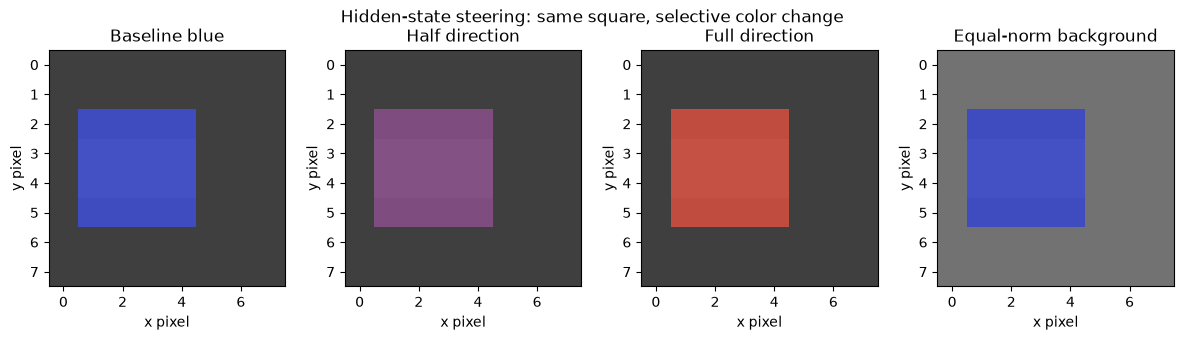

In [ ]:
positive = np.array([[1.,-.4,-.5],[1.,.4,.5]])
negative = positive.copy(); negative[:,0] = -1.
direction = paired_direction(positive, negative)
background_direction = np.array([0.,0.,np.linalg.norm(direction)])
states = np.concatenate([base_state, steer_state(base_state,direction,.5),
                         steer_state(base_state,direction,1.),
                         steer_state(base_state,background_direction,1.)])
images = render_scene(states)
print("Object red-minus-blue:", object_color_score(images,object_mask).round(3))
utils.image_grid(images, ["Baseline blue", "Half direction", "Full direction", "Equal-norm background"],
                 "Hidden-state steering: same square, selective color change")
plt.show()

<details><summary>Help - how should I interpret this?</summary>

The reference pixel scores are -0.5, 0, 0.5 and -0.5. The gray stripe survives. The background control visibly changes the picture but fails the object-color metric. Passing one attribute score does not guarantee an unchanged image.

</details>

## Summary of 2️⃣

Matched differences isolate color in this known state space. Projection removal sets its color component to neutral; it does not remove arbitrary visual concepts from an unknown model.

# 3️⃣ What a low-rank adapter changes

> ##### Learning Objectives
>
> - Implement the visible operations for fit one factor of a rank-one adapter exactly, then inspect its singular directions.
> - Explain the tensor axes and use an independent small-case check.

A LoRA update changes a weight matrix: $W'=W+\alpha BA$, with
$A\in\mathbb R^{r\times d_{in}}$ and $B\in\mathbb R^{d_{out}\times r}$.
For row-vector inputs, outputs are $hW^T+\alpha(hA^T)B^T$.
This distinction is easy to lose when square matrices happen to have matching dimensions.

We fit only $A$ while holding $B$ fixed, on six literal states. This is an exact small linear
least-squares exercise, **not training a diffusion LoRA**. It teaches the parameterization and
its singular directions without an optimization or model budget.

### Exercise - implement `lora_update`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Inputs `left=B [out,rank]`, `right=A [rank,in]`; return the `[out,in]` update.

In [ ]:
def lora_update(left, right, scale=1.0):
    raise NotImplementedError()


tests.test_lora_update(lora_update)

<details><summary>Hint</summary>

The two low-rank factors multiply in output-by-input order.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_lora_update passed!`.
Rank one cannot produce a rank-two update.

</details>


<details><summary>Solution</summary>

```python
def lora_update(left, right, scale=1.0):
    return scale * np.asarray(left) @ np.asarray(right)
```
</details>

### Exercise - implement `adapter_forward`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Apply the base linear map and low-rank branch separately. The batch may be any size.

In [ ]:
def adapter_forward(states, weight, left, right, scale=1.0):
    raise NotImplementedError()


tests.test_adapter_forward(adapter_forward)

<details><summary>Hint</summary>

A row vector multiplies transposed weights.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_adapter_forward passed!`.
The tests use unequal input/output widths so a missing transpose cannot pass.

</details>


<details><summary>Solution</summary>

```python
def adapter_forward(states, weight, left, right, scale=1.0):
    return np.asarray(states) @ np.asarray(weight).T + scale*(np.asarray(states) @ np.asarray(right).T) @ np.asarray(left).T
```
</details>

### Exercise - implement `fit_right_factor`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

With `B=left` fixed, solve for `A` that fits residual targets. Use the minimum-norm least-squares solution. Targets are desired output minus base output, not desired output itself.

In [ ]:
def fit_right_factor(inputs, residual_targets, left):
    raise NotImplementedError()


tests.test_fit_right_factor(fit_right_factor)

<details><summary>Hint</summary>

First express the output residual in the columns of B; then solve `X @ A.T`.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_fit_right_factor passed!`.
For `B=[1,0,0].T` and target `0.6*X[:,0]*B`, the fitted row is `[0.6,0,0]`.

</details>


<details><summary>Solution</summary>

```python
def fit_right_factor(inputs, residual_targets, left):
    coordinates = np.asarray(residual_targets) @ np.linalg.pinv(np.asarray(left)).T
    return np.linalg.lstsq(np.asarray(inputs), coordinates, rcond=None)[0].T
```
</details>

### Exercise - implement `rank_reconstruction`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return the rank-$k$ truncated SVD $U_k\Sigma_kV_k^T$. Keep `rank=0` as an all-zero control.

In [ ]:
def rank_reconstruction(update, rank):
    raise NotImplementedError()


tests.test_rank_reconstruction(rank_reconstruction)

<details><summary>Hint</summary>

Scale columns of U by the corresponding singular values.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_rank_reconstruction passed!`.
Rank zero is zero; full rank reconstructs the update to floating-point precision.

</details>


<details><summary>Solution</summary>

```python
def rank_reconstruction(update, rank):
    u, singular, vt = np.linalg.svd(np.asarray(update), full_matrices=False)
    if not 0 <= rank <= len(singular):
        raise ValueError("rank outside matrix dimensions")
    return (u[:,:rank]*singular[:rank]) @ vt[:rank]
```
</details>


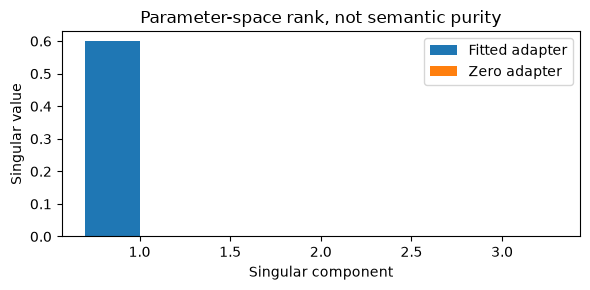

In [ ]:
fit_states = np.array([[1,0,0],[-1,0,0],[1,1,0],[-1,1,0],[1,0,1],[-1,0,1]],dtype=float)
left = np.array([[1.],[0.],[0.]])
residual_targets = np.zeros_like(fit_states); residual_targets[:,0] = .6*fit_states[:,0]
right = fit_right_factor(fit_states,residual_targets,left)
update = lora_update(left,right)
print("Fitted right factor:",right.round(6))
print("Singular values:",np.linalg.svd(update,compute_uv=False).round(6))
fig, ax = plt.subplots(figsize=(6,3))
ax.bar(np.arange(1,4)-.15,np.linalg.svd(update,compute_uv=False),width=.3,label="Fitted adapter")
ax.bar(np.arange(1,4)+.15,np.linalg.svd(np.zeros((3,3)),compute_uv=False),width=.3,label="Zero adapter")
ax.set(xlabel="Singular component",ylabel="Singular value",title="Parameter-space rank, not semantic purity")
ax.legend();fig.tight_layout();plt.show()

<details><summary>Help - how should I interpret this?</summary>

The fitted row is [0.6,0,0], and the spectrum is [0.6,0,0]. Its negative effect on a negative color state below is a consequence of input-dependent weight editing: a rank-one adapter is not the constant addition used in Part 2.

</details>

## Summary of 3️⃣

A low-rank update is input dependent. Its SVD identifies large parameter directions; only behavioral measurements tell us what those directions do.

# 4️⃣ Behavior, side effects and transfer

> ##### Learning Objectives
>
> - Implement the visible operations for compare behavior and side effects, then predict a changed direction before running it.
> - Explain the tensor axes and use an independent small-case check.

A useful edit should change the requested attribute without changing the background.
For each candidate, measure the change in object red-minus-blue and mean absolute RGB change
outside the object. Keep both signed target effect and unsigned collateral change.
Do not combine them into an arbitrary success number.

Predict the direction of the fitted adapter's effect on a **blue** state before running.
An adapter trained to amplify the signed color coordinate will make blue more blue, whereas
adding a positive hidden direction made blue more red. This is our changed-condition test.

### Exercise - implement `background_damage`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return per-image mean absolute RGB error outside the object mask. Inputs are `[batch,H,W,3]`.

In [ ]:
def background_damage(reference_images, edited_images, mask):
    raise NotImplementedError()


tests.test_background_damage(background_damage)

<details><summary>Hint</summary>

Do not average foreground pixels into the collateral-damage score.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_background_damage passed!`.
Changing only an object pixel leaves damage zero.

</details>


<details><summary>Solution</summary>

```python
def background_damage(reference_images, edited_images, mask):
    return np.abs(np.asarray(edited_images)[:,~np.asarray(mask,dtype=bool)] - np.asarray(reference_images)[:,~np.asarray(mask,dtype=bool)]).mean(axis=(1,2))
```
</details>

### Exercise - implement `matched_nuisance_update`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Construct a rank-one, equal-Frobenius-norm control that maps input color into output background. This is a deterministic nuisance control, not a sampled random adapter.

In [ ]:
def matched_nuisance_update(update):
    raise NotImplementedError()


tests.test_matched_nuisance_update(matched_nuisance_update)

<details><summary>Hint</summary>

Put the complete norm at output background / input color.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_matched_nuisance_update passed!`.
For the fitted update, both norms are 0.6; only the control changes background.

</details>


<details><summary>Solution</summary>

```python
def matched_nuisance_update(update):
    control = np.zeros_like(update, dtype=np.float64)
    control[2,0] = np.linalg.norm(update)
    return control
```
</details>


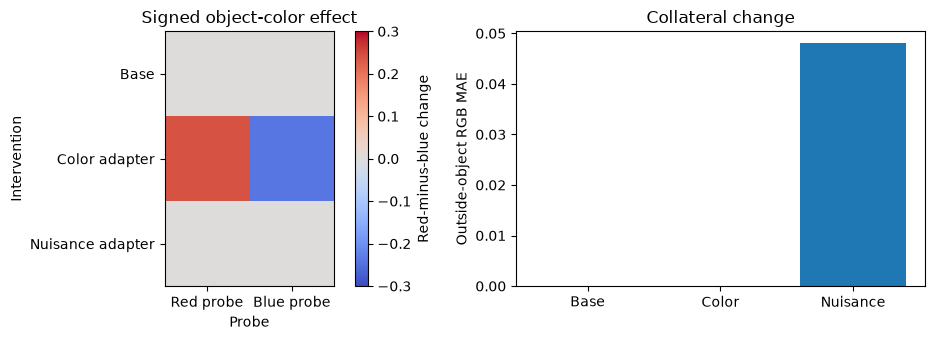

In [ ]:
weight = np.eye(3)
control_update = matched_nuisance_update(update)
probe_states = np.array([[.8,.4,0.],[-.8,.4,0.]])
reference_images = render_scene(probe_states)
real_states = probe_states @ (weight+rank_reconstruction(update,1)).T
control_states = probe_states @ (weight+control_update).T
candidates = [reference_images,render_scene(real_states),render_scene(control_states)]
metrics = np.array([[np.mean(object_color_score(x,object_mask)-object_color_score(reference_images,object_mask)),
                     np.mean(background_damage(reference_images,x,object_mask))] for x in candidates])
# Signed effects cancel across opposite-color probes; keep the two rows visible.
effects = np.stack([object_color_score(x,object_mask)-object_color_score(reference_images,object_mask) for x in candidates])
print("Signed target changes, columns red/blue:",effects.round(3))
print("Background damage:",metrics[:,1].round(3))
fig,axes = plt.subplots(1,2,figsize=(10,3.5))
im=axes[0].imshow(effects,vmin=-.3,vmax=.3,cmap="coolwarm")
axes[0].set(xticks=[0,1],xticklabels=["Red probe","Blue probe"],yticks=range(3),yticklabels=["Base","Color adapter","Nuisance adapter"],title="Signed object-color effect",xlabel="Probe",ylabel="Intervention")
fig.colorbar(im,ax=axes[0],label="Red-minus-blue change")
axes[1].bar(["Base","Color","Nuisance"],metrics[:,1]);axes[1].set(ylabel="Outside-object RGB MAE",title="Collateral change")
fig.tight_layout();plt.show()

<details><summary>Help - how should I interpret this?</summary>

The color adapter produces +0.24 on the red probe and -0.24 on the blue probe; the nuisance adapter produces zero target effect and 0.048 background MAE. Averaging signed target effects would hide both real changes. This matrix, read beside the image grid and SVD, is the primary signature result.

</details>

## Try it yourself

Change only `play_color` from +0.8 to -0.8. Predict the sign of the adapter effect and the
hidden-state addition effect **separately** before running. Then try a large strength that
causes pixel clipping. Does a parameter direction with one singular value still have a linear
image-score effect? Keep the original examples unchanged.

In [ ]:
play_color = -0.8
play_strength = 1.0
play = np.array([[play_color,.4,0.]])
play_images = render_scene(np.concatenate([play,steer_state(play,direction,.3),play @ (np.eye(3)+play_strength*update).T]))
print("Pixel scores base / state-add / weight-edit:",object_color_score(play_images,object_mask).round(3))
utils.image_grid(play_images,["Base","Constant state direction","Input-dependent adapter"],"Predict the changed-color case")
plt.show()

## Summary of 4️⃣

Selectivity requires target and collateral scores, and direction claims require a stated input condition. A singular value alone establishes neither.

# ☆ Bonus

## Limits and the real-model bridge

The study edition teaches matched directions, projection removal, LoRA
factorization, an exact one-factor fit, SVD and independent image scoring. It does **not** train
a UNet adapter, discover h-space, reproduce Concept Sliders, or establish safe concept removal.

Kwon et al. identify a semantic h-space in pretrained diffusion models; Concept Sliders learn
low-rank parameter changes for controlled attributes. These are different intervention sites.
A native follow-on needs fixed prompts/seeds, the exact UNet layer/time and checkpoint, a
specified adapter objective, and independently scored target preservation and collateral
changes across generated images. A learned direction should be checked against matched
nuisance directions and a zero adapter before being described as selective.

Anomaly hunt: can a large stripe or a mask containing background corrupt the pixel metric?
Explain why that is a measurement failure, not evidence that the adapter stopped working.

## Further reading

- [Diffusion Models already have a Semantic Latent Space](https://arxiv.org/abs/2210.10960).
- [Concept Sliders: LoRA Adaptors for Precise Control in Diffusion Models](https://arxiv.org/abs/2311.12092).
- [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685).